# 03. Khám phá Dữ liệu, Xác định Trạng thái Tắc nghẽn và Phân tích Dấu hiệu Tiền tắc nghẽn trên `PEMS08`

> Trả lời trọn vẹn **Câu hỏi Nghiên cứu 1 (RQ1)** thuần trên mạng nghiên cứu chính **`PEMS08`** theo đúng mạch tuyến tính từ trên xuống dưới (phần trước tuyệt đối không dùng khái niệm hay ngưỡng của phần sau). Tập bản đồ thứ hai (`PEMS04`) được giữ độc lập hoàn toàn cho bước kiểm chứng chéo cuối cùng (`NB05`).

### Tóm tắt
* **Câu hỏi dẫn dắt (RQ1):** *Làm thế nào xác định trạng thái tắc nghẽn và trích xuất các dấu hiệu tiền tắc nghẽn trực tiếp từ dữ liệu cảm biến đa biến?*
* **Cấu trúc 5 phần tuyến tính:**
  1. **Phần 1:** Phân tích khám phá đa biến và cấu trúc tương quan trên `PEMS08`.
  2. **Phần 2:** Xác định ngưỡng tắc nghẽn từ Biểu đồ cơ bản và lý giải loại trừ lưu lượng (`Flow`).
  3. **Phần 3:** Phân tích chuyển pha và đánh giá `4` nhóm đặc trưng bổ sung (`7` chỉ báo tiền tắc nghẽn + `4` chu kỳ thời gian `STID`) trên cửa sổ cố định `H = 12` bước (`60 phút`).
  4. **Phần 4:** Phân tích cấu trúc đồ thị — đối chiếu hình học tĩnh (`Betweenness`) và tương tác động lân cận (`In / Out`).
  5. **Phần 5:** Tổng kết Câu hỏi Nghiên cứu 1 và thiết lập đầu vào cho mô hình hóa (`NB04`).

---
## 1. Phân tích Khám phá Đa biến và Cấu trúc Tương quan trên `PEMS08`

Nạp `PEMS08_clean.npz` (`62` ngày từ Thứ Sáu `01/07` đến `31/08/2016`, `17.856` bước đo 5 phút, `170` trạm, `277` cạnh có hướng duy nhất, `0` lỗi tồn đọng). Ta thống kê mô tả, tính **ma trận tương quan Pearson `3 × 3`** trên toàn tập, và trực quan hóa nhịp điệu ngày–tuần của đủ `3` biến trên **`10` trạm có vận tốc trung bình thấp nhất**.

In [1]:
import sys
from pathlib import Path
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bottlenecks import (
    load_cleaned_pems, calibrate_congestion_thresholds, classify_traffic_phases,
    summarize_station_congestion, extract_precongestion_features, extract_time_features,
    evaluate_precongestion_signals, evaluate_dynamic_graph_signals,
)
from src.plots_nb03 import (
    apply_paper_style, plot_pems08_overview, plot_fundamental_and_workday,
    plot_precongestion_trajectories, plot_stid_time_cycles, plot_precongestion_validation, plot_spatial_and_graph,
)

apply_paper_style()
OUT_DIR, FIG_DIR = ROOT / "outputs", ROOT / "outputs" / "figures"
SEED, H_WIN = 42, 12
np.random.seed(SEED)

data, edges = load_cleaned_pems("PEMS08", clean_dir=ROOT / "datasets/cleaned", raw_dir=ROOT / "datasets/data")
T, N, _ = data.shape
flow, occ, spd = data[:, :, 0], data[:, :, 1], data[:, :, 2]

desc_df = pd.DataFrame([
    {"Biến": n, "Đơn vị": u, "TB": round(float(data[:, :, i].mean()), 4), "ĐLC": round(float(data[:, :, i].std()), 4), "Min": round(float(data[:, :, i].min()), 4), "Trung vị": round(float(np.median(data[:, :, i])), 4), "Max": round(float(data[:, :, i].max()), 4)}
    for i, (n, u) in enumerate([("Flow", "xe/5p"), ("Occupancy", "[0, 1]"), ("Speed", "mph")])
])
corr_df = pd.DataFrame({"Flow": flow.ravel(), "Occupancy": occ.ravel(), "Speed": spd.ravel()}).corr().round(4)

slow10 = np.argsort(spd.mean(axis=0))[:10]
t_all = np.arange(T)
hr_all, dow_all = (t_all % 288) // 12, ((t_all // 288) + 4) % 7
mat_spd = np.array([[spd[(dow_all == d) & (hr_all == h)][:, slow10].mean() for h in range(24)] for d in range(7)])

print(f"PEMS08 sạch: T = {T:,} bước (62 ngày), N = {N} trạm, E = {len(edges)} cạnh có hướng duy nhất.")
print(f"Top 10 trạm vận tốc TB thấp nhất: {slow10.tolist()}")
print(f"Vận tốc TB Top 10 — Cao điểm sáng T2–T6 (07–09h): {mat_spd[:5, 7:10].mean():.2f} mph | Chiều (14–18h): {mat_spd[:5, 14:19].mean():.2f} mph | Thấp nhất Thứ 6 lúc {int(np.argmin(mat_spd[4])):02d}h: {mat_spd[4].min():.2f} mph | Cuối tuần TB: {mat_spd[5:].mean():.2f} mph")
display(desc_df)
display(corr_df)

PEMS08 sạch: T = 17,856 bước (62 ngày), N = 170 trạm, E = 277 cạnh có hướng duy nhất.
Top 10 trạm vận tốc TB thấp nhất: [22, 167, 13, 14, 4, 71, 128, 65, 100, 117]
Vận tốc TB Top 10 — Cao điểm sáng T2–T6 (07–09h): 48.66 mph | Chiều (14–18h): 45.45 mph | Thấp nhất Thứ 6 lúc 15h: 37.55 mph | Cuối tuần TB: 59.75 mph


,Biến,Đơn vị,TB,ĐLC,Min,Trung vị,Max
0,Flow,xe/5p,230.8092,146.1292,0.0,215.0000,1147.0000
1,Occupancy,"[0, 1]",0.0651,0.0459,0.0,0.0601,0.8955
2,Speed,mph,63.7633,6.6499,3.0,64.9000,82.3000


,Flow,Occupancy,Speed
Flow,1.0000,0.6735,-0.2968
Occupancy,0.6735,1.0000,-0.7531
Speed,-0.2968,-0.7531,1.0000


Đã lưu biểu đồ: nb03_pems08_overview.png


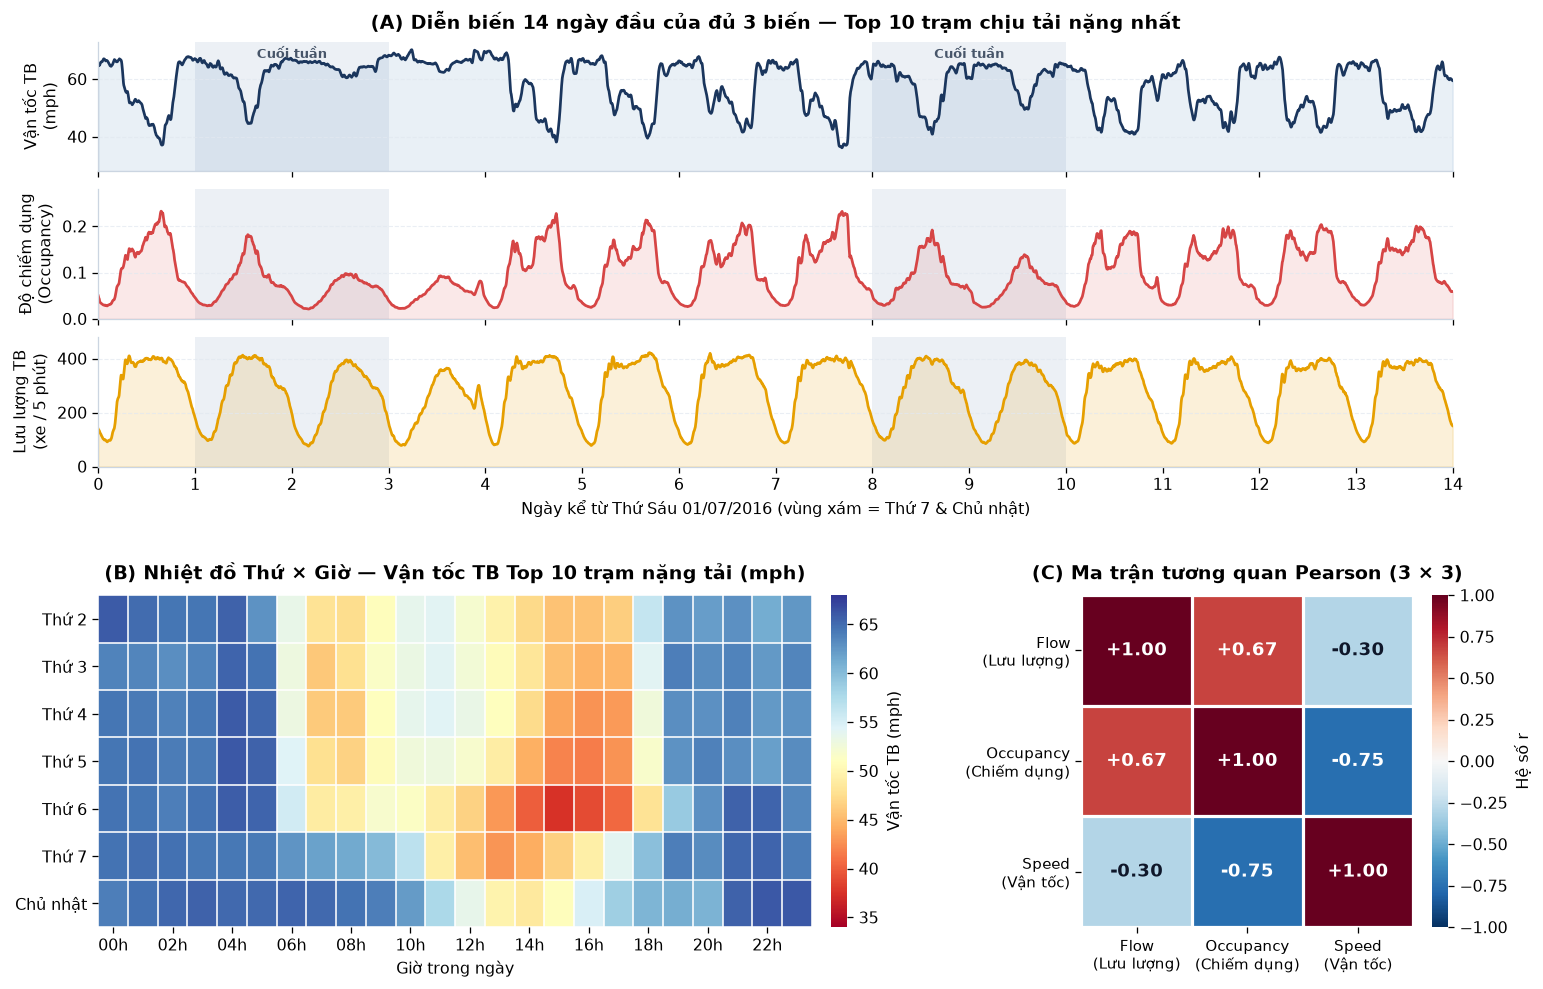

In [2]:
plot_pems08_overview(flow, occ, spd, slow10, mat_spd, corr_df, FIG_DIR / "nb03_pems08_overview.png")

> **Nhận xét (Khám phá đa biến & Cấu trúc tương quan trên `PEMS08`):**
>
> * **Hiện rõ hai khung cao điểm sáng–chiều và tính đối gương `Speed – Occupancy`:** Trên `10` trạm chịu tải nặng nhất, Hình 1A–B ghi nhận rõ hai nhịp giảm tốc ngày thường là **cao điểm sáng (`07–09h`, TB `48,66 mph`)** và **cao điểm chiều (`14–18h`, TB `45,45 mph`, thấp nhất Thứ Sáu lúc `15h` xuống `37,55 mph`)**, trong khi cuối tuần duy trì TB **`59,75 mph`**. Mỗi lần `Speed` tụt sâu đều đi kèm đỉnh `Occupancy` tăng vọt đối xứng.
>
> * **Ma trận tương quan Pearson `3 × 3` (Hình 1C):** `Occupancy` tương quan nghịch chặt với `Speed` (**`r = -0,7531`**), mạnh gấp `2,5` lần `Flow – Speed` (`r = -0,2968`); còn `Flow – Occupancy` đạt `r = +0,6735`.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Làm thế nào xác định ranh giới **tắc nghẽn thực** (`Tắc thực` vs. `Thông thoáng`) bằng công thức tự hiệu chỉnh từ Biểu đồ cơ bản `PEMS08`, và vì sao không chọn `Flow` làm điều kiện phân ngưỡng?

---
## 2. Xác định Ngưỡng Tắc nghẽn từ Biểu đồ Cơ bản và Lý giải Loại trừ Lưu lượng

Phần này xác định ranh giới nhị phân giữa **`Tắc nghẽn thực` ($C_i(t) = 1$)** và **`Thông thoáng` ($C_i(t) = 0$)** bằng công thức hướng dữ liệu trực tiếp trên `PEMS08` (`calibrate_congestion_thresholds`), kết hợp quy chuẩn liên bang Hoa Kỳ và lý thuyết Biểu đồ cơ bản (**FHWA 23 CFR Part 490**; **Chen et al., 2004**; **Choe et al., 2002**; **Cassidy & Bertini, 1999**):

1. **Ngưỡng vận tốc tắc ($v_{\text{cong}}$):** Tính vận tốc dòng tự do $v_{\text{ff}} = \text{median}(v \mid o < 0{,}05)$, áp dụng quy chuẩn **FHWA (23 CFR Part 490 / NPMRDS)** xác định tắc nghẽn/chậm trễ khi vận tốc rơi xuống dưới **`60%` tốc độ tự do** (tức giảm hơn `40%`): $v_{\text{cong}} = 0{,}60\,v_{\text{ff}}$. Trên `PEMS08`, cách tính theo tỷ lệ này tự khớp sát mốc `~40 mph` của **Chen et al. (2004)**.
2. **Ngưỡng chiếm dụng tối thiểu ($o_{\text{sat}}$):** Từ đường cong lưu lượng trung bình $Q(o)$ trên Biểu đồ cơ bản, tìm đỉnh công suất $Q_{\max}$ tại $o_{\text{crit}}$ và lấy điểm sớm nhất trên nhánh đi lên đạt **$90\%$ công suất cực đại ($Q(o) \ge 0{,}90\,Q_{\max}$)** — ước lượng hướng dữ liệu cho dải bão hòa `11%–15%` (**Choe et al., 2002 / HCM**) nhằm lọc nhiễu xe chạy chậm khi đường vắng.
3. **Điều kiện Tắc nghẽn thực:**
   $$C_i(t) = \mathbb{I}\!\left[\, v_i(t) < v_{\text{cong}} \;\land\; o_i(t) \ge o_{\text{sat}} \,\right]$$

In [3]:
th = calibrate_congestion_thresholds(flow, occ, spd)
cg = (spd < th.v_cong) & (occ >= th.o_sat)

th_df = pd.DataFrame([
    {"Tham số tự tính trên PEMS08": "Vận tốc tự do (v_ff = median | Occ < 0,05)", "Giá trị": f"{th.v_ff:.2f} mph", "Cơ sở & Đối chiếu lý thuyết": "Tốc độ dòng tự do đặc trưng của mạng"},
    {"Tham số tự tính trên PEMS08": "Ngưỡng tắc nghẽn (v_cong = 0,60 × v_ff)", "Giá trị": f"{th.v_cong:.2f} mph", "Cơ sở & Đối chiếu lý thuyết": "Quy chuẩn FHWA (<60% FFS); tự khớp ~40 mph (Chen 2004)"},
    {"Tham số tự tính trên PEMS08": "Đỉnh công suất Biểu đồ cơ bản (o_crit / Q_max)", "Giá trị": f"{th.o_crit:.4f} ({th.peak_flow:.1f} xe/5p)", "Cơ sở & Đối chiếu lý thuyết": "Điểm bắt đầu hiệu ứng Capacity Drop (Cassidy 1999)"},
    {"Tham số tự tính trên PEMS08": "Ngưỡng chiếm dụng tối thiểu (o_sat tại 90% Q_max)", "Giá trị": f"{th.o_sat:.4f} ({th.o_sat*100:.2f}%)", "Cơ sở & Đối chiếu lý thuyết": "Ước lượng hướng dữ liệu khớp dải 11%–15% (Choe 2002 / HCM)"},
])

m_bf = (occ >= 0.10) & (occ < 0.15) & (spd >= 55.0)
m_pk = (occ >= 0.15) & (occ < 0.20)
m_jm = (occ >= 0.30) & (spd < th.v_cong)
m_fb = (flow >= 300) & (flow <= 450)
y_slow = (spd < th.v_cong).astype(int).ravel()
cap_drop_pct = (flow[m_jm].mean() / flow[m_pk].mean() - 1.0) * 100.0

flow_proof_df = pd.DataFrame([
    {"Trạng thái giao thông": "Đông nhưng thông thoáng (Occ 0,10–0,15 & Speed ≥ 55)", "Số điểm": f"{int(m_bf.sum()):,}", "Flow TB / TV": f"{flow[m_bf].mean():.1f} / {np.median(flow[m_bf]):.1f}", "Speed TB": round(float(spd[m_bf].mean()), 1)},
    {"Trạng thái giao thông": "Vùng đỉnh công suất (Occ 0,15–0,20)", "Số điểm": f"{int(m_pk.sum()):,}", "Flow TB / TV": f"{flow[m_pk].mean():.1f} / {np.median(flow[m_pk]):.1f}", "Speed TB": round(float(spd[m_pk].mean()), 1)},
    {"Trạng thái giao thông": "Tắc cứng quá tải nặng (Occ ≥ 0,30 & Speed < v_cong)", "Số điểm": f"{int(m_jm.sum()):,}", "Flow TB / TV": f"{flow[m_jm].mean():.1f} / {np.median(flow[m_jm]):.1f}", "Speed TB": round(float(spd[m_jm].mean()), 1)},
])

n_low, n_cg = int((spd < th.v_cong).sum()), int(cg.sum())
n_empty_slow = n_low - n_cg
print(f"Speed < {th.v_cong:.2f} mph: {n_low:,} | Tắc thực (C=1): {n_cg:,} ({cg.mean()*100:.2f}%, {cg[(hr_all >= 5) & (hr_all <= 23)].sum() / n_cg * 100:.2f}% trong 05–23h) | Loại chậm đường vắng: {n_empty_slow:,}")
print(f"Capacity Drop: {cap_drop_pct:+.1f}% | Occ AUC = {roc_auc_score(y_slow, occ.ravel()):.4f} vs Flow AUC = {roc_auc_score(y_slow, flow.ravel()):.4f} | Dải Flow [300, 450] ({int(m_fb.sum()):,} điểm): {(spd[m_fb] >= 55).mean()*100:.1f}% thông thoáng, chỉ {(spd[m_fb] < th.v_cong).mean()*100:.1f}% tắc.")
display(th_df)
display(flow_proof_df)

Speed < 40.26 mph: 63,755 | Tắc thực (C=1): 59,003 (1.94%, 99.51% trong 05–23h) | Loại chậm đường vắng: 4,752
Capacity Drop: -13.7% | Occ AUC = 0.9781 vs Flow AUC = 0.7586 | Dải Flow [300, 450] (672,898 điểm): 90.7% thông thoáng, chỉ 3.4% tắc.


,Tham số tự tính trên PEMS08,Giá trị,Cơ sở & Đối chiếu lý thuyết
0,"Vận tốc tự do (v_ff = median | Occ < 0,05)",67.10 mph,Tốc độ dòng tự do đặc trưng của mạng
1,"Ngưỡng tắc nghẽn (v_cong = 0,60 × v_ff)",40.26 mph,Quy chuẩn FHWA (<60% FFS); tự khớp ~40 mph (Chen 2004)
2,Đỉnh công suất Biểu đồ cơ bản (o_crit / Q_max),0.1675 (438.6 xe/5p),Điểm bắt đầu hiệu ứng Capacity Drop (Cassidy 1999)
3,Ngưỡng chiếm dụng tối thiểu (o_sat tại 90% Q_max),0.1325 (13.25%),Ước lượng hướng dữ liệu khớp dải 11%–15% (Choe 2002 / HCM)


,Trạng thái giao thông,Số điểm,Flow TB / TV,Speed TB
0,"Đông nhưng thông thoáng (Occ 0,10–0,15 & Speed ≥ 55)","235,588",392.9 / 400.0,61.6
1,"Vùng đỉnh công suất (Occ 0,15–0,20)","56,320",433.6 / 449.0,50.1
2,"Tắc cứng quá tải nặng (Occ ≥ 0,30 & Speed < v_cong)","13,206",374.2 / 367.0,23.7


Đã lưu biểu đồ: nb03_fundamental_and_workday.png


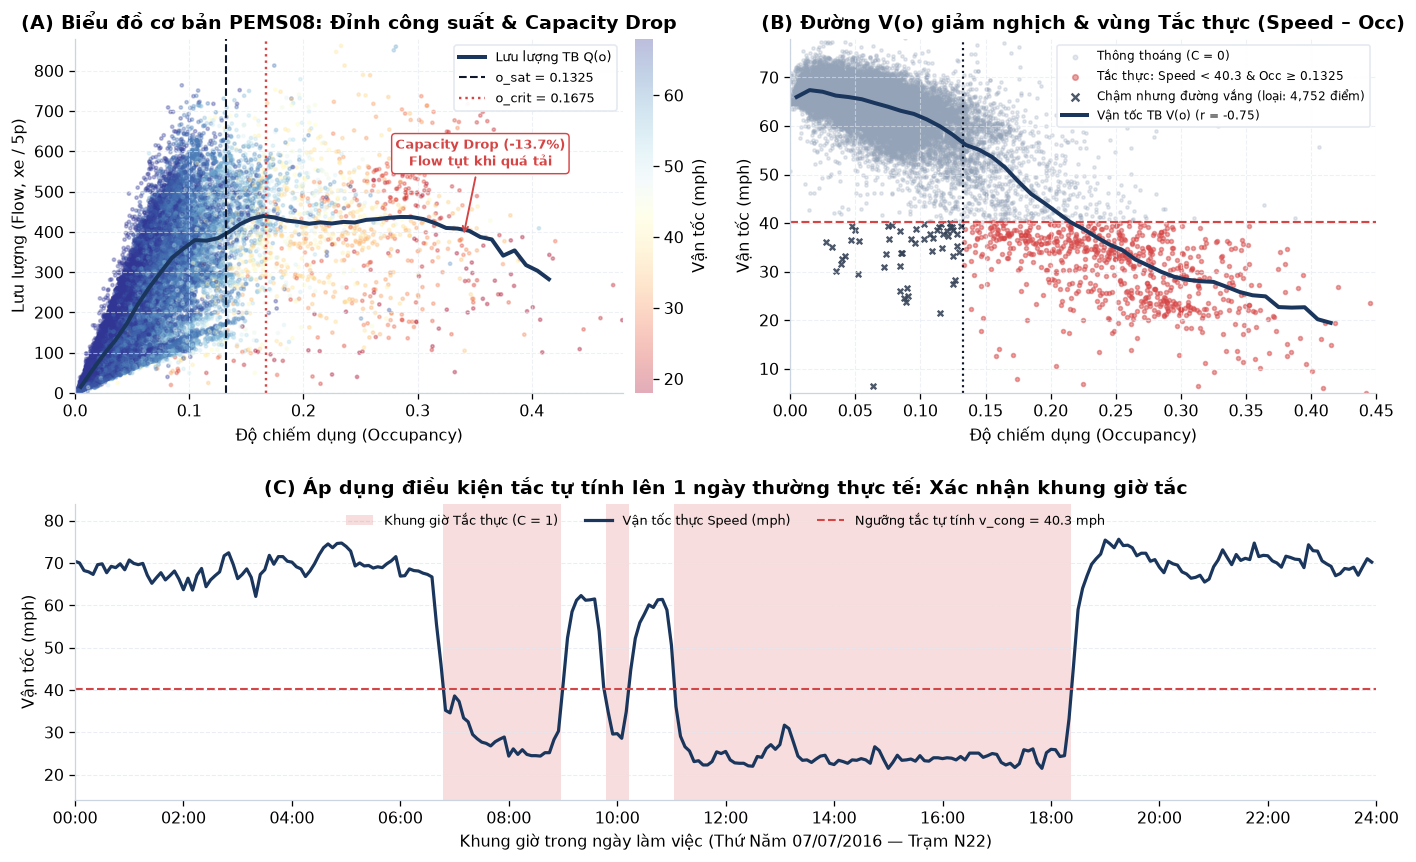

In [4]:
plot_fundamental_and_workday(flow, occ, spd, cg, th, float(corr_df.loc["Occupancy", "Speed"]), cap_drop_pct, n_empty_slow, FIG_DIR / "nb03_fundamental_and_workday.png", seed=SEED)

> **Nhận xét (Điều kiện tắc nghẽn tự tính & Chứng minh loại `Flow`):**
>
> * **Tự tính ngưỡng khớp chuẩn FHWA & PeMS:** Từ `PEMS08` tự rút ra $v_{\text{cong}} = \mathbf{40{,}26\text{ mph}}$ (`60%` tốc độ tự do `67,10 mph`) và $o_{\text{sat}} = \mathbf{0{,}1325}$ (`90%` đỉnh công suất $Q_{\max} = 438{,}6$). Trên Hình 2B, đường vận tốc trung bình $V(o)$ giảm đơn điệu theo `Occupancy` (`r = -0,75`), còn cặp ngưỡng tách sạch **`59.003` điểm Tắc thực (`1,94%`, `99,51%` trong `05–23h`)** khỏi `4.752` điểm chạy chậm khi đường vắng (dấu `×`) và khoanh đúng khung giờ tắc ngày `07/07/2016` tại `N22` (Hình 2C).
>
> * **Vì sao KHÔNG chọn `Flow` làm điều kiện tắc nghẽn (*Capacity Drop* — Cassidy & Bertini, 1999):** Khi tắc cứng quá tải (`Occ ≥ 0,30`, `Speed TB = 23,7 mph`), `Flow` tụt ngược **`-13,7%`** so với vùng đỉnh (`433,6 → 374,2 xe/5p`, trung vị `367,0`, thấp hơn cả lúc chạy thoáng `61,6 mph` có trung vị `400,0`). Trong dải `Flow [300, 450]` (`672.898` điểm), **`90,7%` đang thông thoáng** và chỉ `3,4%` tắc (`Flow AUC = 0,7586` kém xa `Occ AUC = 0,9781`).
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Trước khi dòng xe rơi vào trạng thái Tắc thực ($C_i(t) = 1$) ở Phần 2, quá trình chuyển pha diễn biến ra sao và những chỉ báo định lượng nào giúp nhận biết sớm tình trạng tiền tắc nghẽn trên cửa sổ cố định `60 phút`?

---
## 3. Phân tích Chuyển pha và Đánh giá Hệ chỉ báo Tiền tắc nghẽn

Từ điều kiện Tắc nghẽn thực $C_i(t) = 1$ ở Phần 2, ta xác lập **Pha chuyển tiếp tiền tắc nghẽn** (*Synchronized Flow* — **Kerner, 2004**) bằng quy ước giảm `20%` tốc độ tự do ($v_{\text{sync}} = 0{,}80\,v_{\text{ff}} = 53{,}68\text{ mph}$): vùng chưa tắc ($C_i(t) = 0$) nhưng $v_i(t) < v_{\text{sync}} \lor o_i(t) \ge o_{\text{sat}}$.

Đồng bộ với ma trận đầu vào chuẩn của `PeMS` ở `NB04`, ta cố định cửa sổ nhân quả **`H = 12` bước (`60 phút` quá khứ $[t - 11, t]$)** và kiểm chứng đầy đủ **`4` nhóm đặc trưng bổ sung** (chốt trọn bộ `14` đặc trưng đầu vào gồm `3` biến gốc + `7` chỉ báo tiền tắc nghẽn + `4` chu kỳ thời gian):
* **Nhóm 1 — Dao động khử dốc (`3` biến):** Khử xu hướng tuyến tính (*detrending*) rồi đo độ rung lắc phần dư của `Flow, Occupancy, Speed` (*Stop-and-Go* — **Kerner, 2004**).
* **Nhóm 2 — Liên kết Đa biến (`2` cặp):** Kế thừa kết luận của **Chattopadhyay & Gupta (*Royal Society Open Science*, 2026)** rằng các chỉ báo đa biến vượt trội chỉ báo đơn biến, ta chọn 2 cặp tương quan chéo nhất quán nhất theo Biểu đồ cơ bản là **`occ_spd_corr` (`-corr(Occ, Speed)`)** và **`flow_occ_decouple` (`-corr(Flow, Occ)`)**.
* **Nhóm 3 — Độ dốc có dấu (`2` biến):** Lấy hệ số góc có dấu của `Occupancy` và `Speed` tách ra từ bước khử xu hướng ở Nhóm 1 (kết hợp nguyên lý **California / McMaster** — Payne & Tignor, 1978; Persaud & Hall, 1989) để phân biệt chiều tụt tốc vào tắc với chiều hồi phục thoát tắc.
* **Nhóm 4 — Chu kỳ Thời gian (`4` biến — STID, Shao et al., *CIKM* 2022):** Mã hóa tuần hoàn giờ trong ngày (`tod_sin, tod_cos`) và thứ trong tuần (`dow_sin, dow_cos`) nhằm cung cấp bối cảnh khung giờ cao điểm cho mô hình dự báo (được đặt đánh giá song song ngang hàng cùng 3 nhóm trên trước khi gộp đủ `14` đặc trưng).

| Nhóm đặc trưng | Tên đặc trưng | Ý nghĩa giao thông | Cách tính (`H = 12` = `60 phút`) |
| :--- | :--- | :--- | :--- |
| **1. Dao động khử dốc** *(Kerner, 2004)* | `occ_rstd`, `spd_rstd`, `flow_rstd` | Độ rung lắc thất thường của mật độ, vận tốc, lưu lượng | Trừ xu hướng thẳng rồi lấy độ lệch chuẩn phần dư |
| **2. Liên kết Đa biến** *(Chattopadhyay & Gupta, 2026)* | `occ_spd_corr`, `flow_occ_decouple` | Liên kết nghịch `Occ–Speed` & đứt gãy đồng biến `Flow–Occ` | `-corr(Occ, Speed)` và `-corr(Flow, Occ)` trong `60 phút` |
| **3. Độ dốc có dấu** *(California / McMaster)* | `occ_slope`, `spd_slope` | Chiều tích tụ mật độ & trượt/hồi phục vận tốc (`> 0` thoát tắc) | Hệ số góc tuyến tính theo bước 5 phút |
| **4. Chu kỳ Thời gian** *(STID — Shao et al., 2022)* | `tod_sin/cos`, `dow_sin/cos` | Định danh khung giờ cao điểm sáng–chiều và ngày thường/cuối tuần | Mã hóa lượng giác `sin/cos` chu kỳ `24h` và `7 ngày` |

In [5]:
phase, cg, sync = classify_traffic_phases(spd, occ, th)
csd = extract_precongestion_features(data, window=H_WIN)
time4 = extract_time_features(T, N, start_dow=4)
ev = evaluate_precongestion_signals(data, cg, sync, csd, time4=time4, window=H_WIN, post_steps=18, lead_univar=3, seed=SEED)
rel_steps, curves, csd_df, lrt_df = ev["rel_steps"], ev["curves"], ev["csd_df"], ev["lrt_df"]

idx_0, idx_p60 = int(np.where(rel_steps == 0)[0][0]), int(np.where(rel_steps == 12)[0][0])
print(f"Ngưỡng Pha chuyển tiếp (0,80 × v_ff): v_sync = {th.v_sync:.2f} mph | Pha chuyển tiếp: {int(sync.sum()):,} điểm ({sync.mean()*100:.2f}%)")
print(f"Toàn mạng 170 trạm (-60p → +90p): Tổng ca khởi phát = {ev['n_all_onsets']:,} | Ca mới sạch (60p trước thông) = {ev['n_fresh_onsets']:,} ({ev['n_fresh_onsets']/ev['n_all_onsets']*100:.1f}%)")
print(f"Bội số tăng tại t = 0p so với -60p: occ_rstd = {curves['occ_rstd'][idx_0]/curves['occ_rstd'][0]:.2f}x | spd_rstd = {curves['spd_rstd'][idx_0]/curves['spd_rstd'][0]:.2f}x | flow_rstd = {curves['flow_rstd'][idx_0]/curves['flow_rstd'][0]:.2f}x")
print(f"Nhóm 2 đa biến (-60p → 0p): occ_spd_corr = {curves['occ_spd_corr'][0]:+.3f} → {curves['occ_spd_corr'][idx_0]:+.3f} | flow_occ_decouple = {curves['flow_occ_decouple'][0]:+.3f} → {curves['flow_occ_decouple'][idx_0]:+.3f}")
print(f"Pha hồi phục tại t = +60p: occ_rstd còn {curves['occ_rstd'][idx_p60]/curves['occ_rstd'][0]:.2f}x nền, nhưng spd_slope = {curves['spd_slope'][idx_p60]:+.2f} mph/5p & occ_slope = {curves['occ_slope'][idx_p60]:+.4f}/5p")
hr_cg = np.array([cg[hr_all == h].mean() * 100.0 for h in range(24)])
dow_cg = np.array([cg[dow_all == d].mean() * 100.0 for d in range(7)])
h_am, h_pm = int(np.argmax(hr_cg[6:11]) + 6), int(np.argmax(hr_cg[12:20]) + 12)
day_names = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "Chủ nhật"]
d_pk = int(np.argmax(dow_cg))
print(f"Nhóm 4 (STID) P(C=1) toàn mạng 170 trạm — Đỉnh sáng {h_am:02d}h: {hr_cg[h_am]:.2f}% | Đỉnh chiều {h_pm:02d}h: {hr_cg[h_pm]:.2f}% | Đêm 00–04h TB: {hr_cg[:5].mean():.2f}%")
print(f"Nhóm 4 (STID) P(C=1) theo thứ — T2–T6 TB: {dow_cg[:5].mean():.2f}% (cao nhất {day_names[d_pk]}: {dow_cg[d_pk]:.2f}%) vs Cuối tuần TB: {dow_cg[5:].mean():.2f}% (gấp {dow_cg[:5].mean()/dow_cg[5:].mean():.1f}x)")
display(csd_df)
display(lrt_df)

Ngưỡng Pha chuyển tiếp (0,80 × v_ff): v_sync = 53.68 mph | Pha chuyển tiếp: 152,114 điểm (5.01%)
Toàn mạng 170 trạm (-60p → +90p): Tổng ca khởi phát = 6,611 | Ca mới sạch (60p trước thông) = 3,199 (48.4%)
Bội số tăng tại t = 0p so với -60p: occ_rstd = 2.29x | spd_rstd = 2.37x | flow_rstd = 1.12x
Nhóm 2 đa biến (-60p → 0p): occ_spd_corr = +0.552 → +0.905 | flow_occ_decouple = -0.648 → +0.135
Pha hồi phục tại t = +60p: occ_rstd còn 2.41x nền, nhưng spd_slope = +0.85 mph/5p & occ_slope = -0.0042/5p
Nhóm 4 (STID) P(C=1) toàn mạng 170 trạm — Đỉnh sáng 07h: 3.42% | Đỉnh chiều 17h: 7.18% | Đêm 00–04h TB: 0.05%
Nhóm 4 (STID) P(C=1) theo thứ — T2–T6 TB: 2.38% (cao nhất Thứ 6: 3.07%) vs Cuối tuần TB: 0.87% (gấp 2.7x)


,Nhóm,Chỉ báo,Trung vị Sắp tắc,Trung vị Thông,Hệ số tăng,AUC (Thông sạch 60p),RR Top 10%,AUC (Speed ≥ 55 mph),p (Mann–Whitney)
0,Nhóm 1 (Dao động),occ_rstd,0.0153,0.0033,4.62x,0.9318,36.42x,0.8613,< 1e-300
1,Nhóm 1 (Dao động),spd_rstd,2.6175,0.5084,5.15x,0.9044,25.67x,0.7983,< 1e-300
2,Nhóm 1 (Dao động),flow_rstd,21.2958,11.4390,1.86x,0.7784,4.77x,0.7774,< 1e-300
3,Nhóm 2 (Liên kết),occ_spd_corr,0.8392,0.3549,2.36x,0.8490,13.54x,0.7304,< 1e-300
4,Nhóm 2 (Liên kết),flow_occ_decouple,-0.5054,-0.9376,Đổi dấu,0.8217,10.49x,0.6439,< 1e-300
5,Nhóm 3 (Độ dốc),occ_slope,0.0026,-0.0000,Đổi dấu,0.8101,17.92x,0.6557,< 1e-300
6,Nhóm 3 (Độ dốc),spd_slope,-0.5839,-0.0017,Đổi dấu,0.8113,21.56x,0.6372,< 1e-300
7,Nhóm 4 (STID),"tod (sin,cos)",—,—,Chu kỳ 24h,0.6878,1.86x,0.6782,< 1e-300
8,Nhóm 4 (STID),"dow (sin,cos)",—,—,Chu kỳ 7 ngày,0.5635,1.18x,0.5618,4.66e-19


,Tầm cảnh báo (Δt),Raw 3 biến,+Nhóm 1 (Dao động),+Nhóm 2 (Liên kết),+Nhóm 3 (Độ dốc),+Nhóm 4 (STID),Gộp 4 nhóm (14),Tăng PR-AUC (%),p (LRT df=11)
0,5 phút,0.1888,0.2245,0.2156,0.2091,0.1832,0.2486,+31.66%,2.70e-56
1,15 phút,0.1483,0.1689,0.1637,0.1612,0.1489,0.1817,+22.51%,2.63e-130
2,30 phút,0.1168,0.1346,0.1261,0.1251,0.1168,0.1448,+23.99%,8.85e-241


Đã lưu biểu đồ: nb03_precongestion_trajectories.png


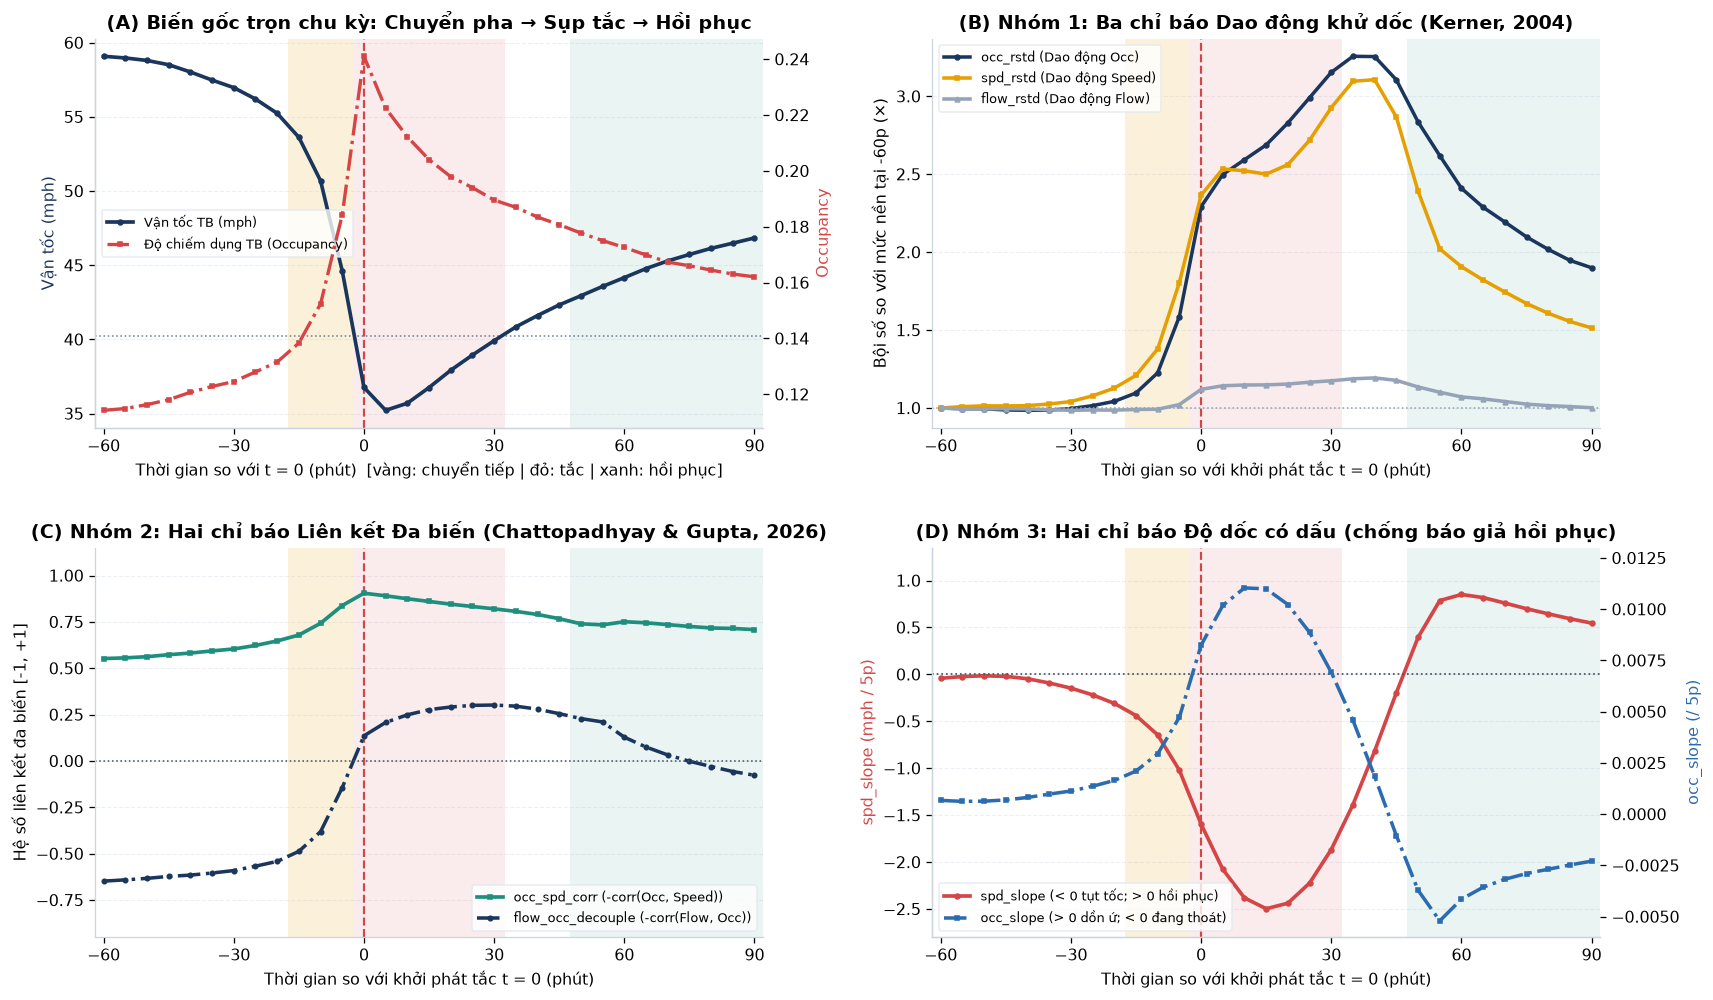

In [6]:
plot_precongestion_trajectories(rel_steps, curves, th, FIG_DIR / "nb03_precongestion_trajectories.png")

Đã lưu biểu đồ: nb03_stid_time_cycles.png


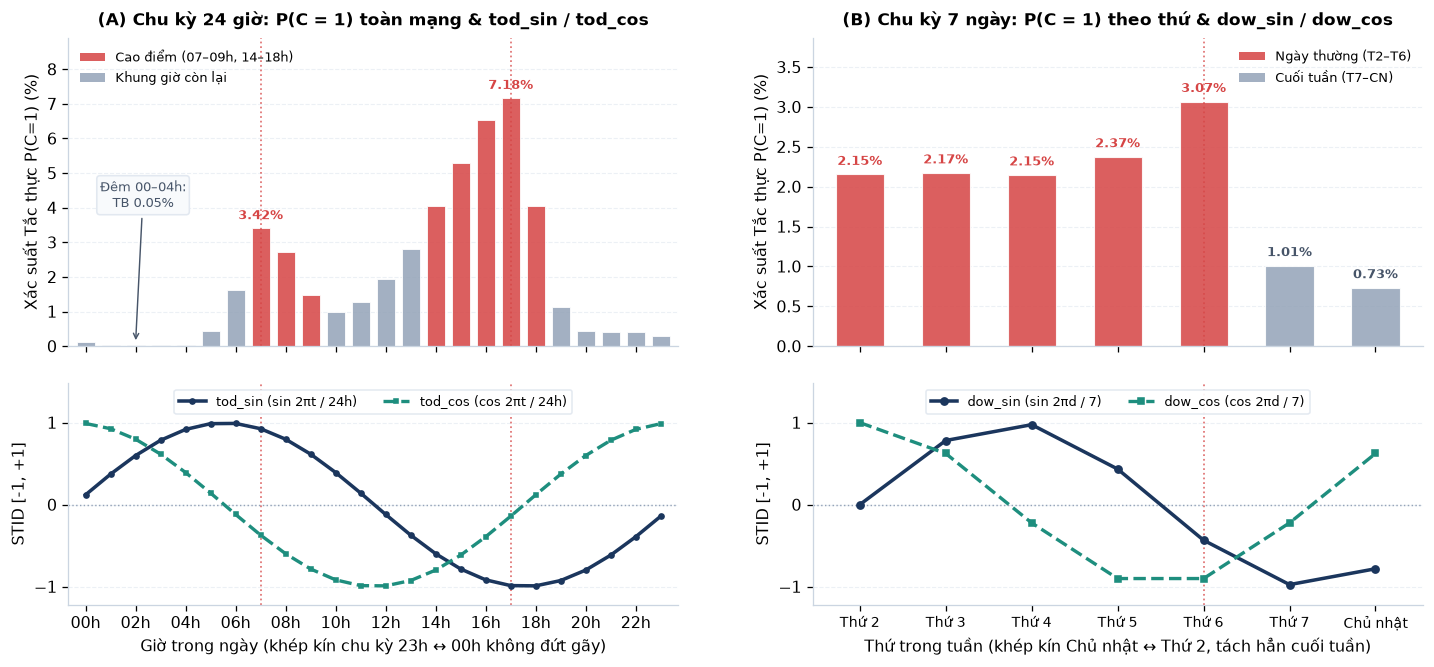

In [7]:
plot_stid_time_cycles(cg, hr_all, dow_all, time4, FIG_DIR / "nb03_stid_time_cycles.png")

Đã lưu biểu đồ: nb03_precongestion_validation.png


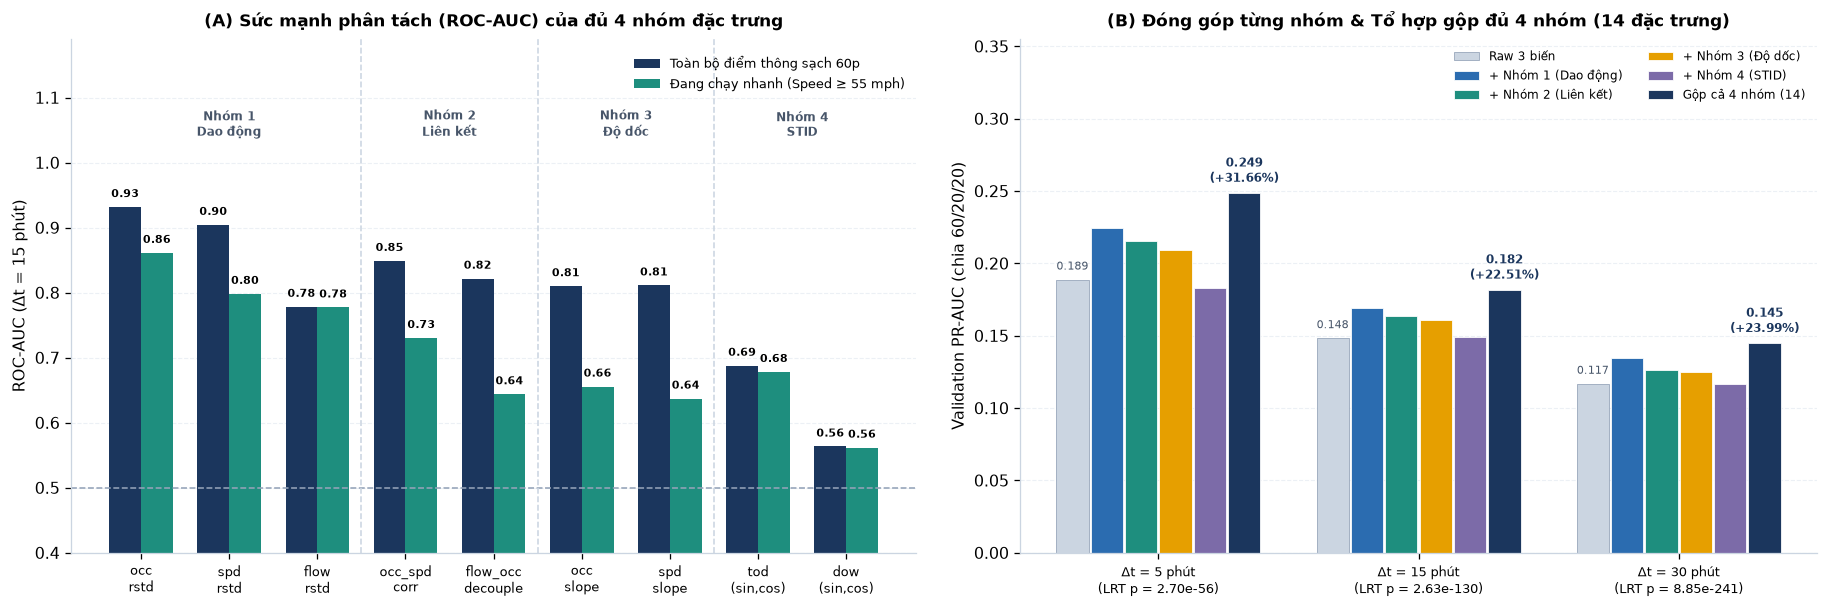

In [8]:
plot_precongestion_validation(csd_df, lrt_df, FIG_DIR / "nb03_precongestion_validation.png")

> **Nhận xét (Diễn biến trọn chu kỳ, Chu kỳ thời gian Nhóm 4 & Đóng góp từng bước của đủ `14` đặc trưng):**
>
> * **Hiệu quả cao và đồng đều trên cả `7` chỉ báo tiền tắc nghẽn — không còn biến yếu (Hình 3a & 3c):** Kế thừa kết luận của **Chattopadhyay & Gupta (2026)**, hai chỉ báo liên kết đa biến Nhóm 2 đều tăng mạnh trước `t = 0`: **`occ_spd_corr`** vọt từ **`+0,552 → +0,905`** (`AUC = 0,8490`, `RR = 13,54×`, vẫn `0,7304` khi `Speed ≥ 55 mph`) và **`flow_occ_decouple`** đảo chiều bứt phá từ **`-0,648 → +0,135`** (`AUC = 0,8217`, `RR = 10,49×`, `≥ 55 mph: 0,6439`). Toàn bộ **`7` chỉ báo đều đạt `AUC = 0,78–0,93`** ($p < 10^{-300}$).
>
> * **Tách bạch pha vào tắc và pha hồi phục trên trọn chu kỳ `-60p → +90p` (`n = 3.199` ca mới sạch, Hình 3a):** Trước `t = 0`, `occ_rstd` và `spd_rstd` tăng vọt **`2,29× – 2,37×`** (còn `flow_rstd` chỉ tăng `1,12×`). Khi bước sang pha hồi phục (`t = +60p`, vùng xanh), dù `occ_rstd` vẫn còn cao gấp **`2,41×` nền**, cặp độ dốc lập tức **đảo dấu đối xứng** (`spd_slope = +0,85 mph/5p` và `occ_slope = -0,0042/5p`), giúp phân biệt rạch ròi giữa **sập tốc vào tắc** và **thoát tắc hồi phục**.
>
> * **Nhóm 4 (`STID` — Shao et al., 2022) cung cấp bối cảnh chu kỳ bền vững không suy giảm theo vận tốc (Hình 3b & 3c-A):** Trên toàn mạng `170` trạm, xác suất tắc thực `P(C = 1)` phân hóa mạnh theo chu kỳ ngày — đỉnh sáng `07h = 3,42%` và đỉnh chiều `17h = 7,18%` so với đêm `00–04h` TB `0,05%`; theo tuần, `T2–T6` TB `2,38%` (cao nhất Thứ Sáu `3,07%`), gấp `2,7×` cuối tuần (`0,87%`). Khi đặt chung vào bảng `ROC-AUC` cùng `3` nhóm đầu (Hình 3c-A), cặp `tod (sin,cos)` đạt **`0,6878`** (giữ gần nguyên **`0,6782`** ngay cả khi `Speed ≥ 55 mph`) và `dow (sin,cos)` đạt **`0,5635`** (`0,5618` khi `≥ 55 mph`) — cho thấy Nhóm 4 đóng vai trò tiên nghiệm bối cảnh thời gian ổn định, bổ trợ cho `3` nhóm cảm biến vật lý (`AUC = 0,78–0,93`).
>
> * **So sánh đóng góp từng nhóm & hiệu ứng cộng hưởng khi gộp đủ `4` nhóm (`14` đặc trưng, Hình 3c-B):** Đặt cả `4` nhóm độc lập lên nền `Raw 3 biến` (`0,1888 / 0,1483 / 0,1168` ở `5p / 15p / 30p`) cho thứ hạng nhất quán trên mọi tầm cảnh báo: **Nhóm 1 Dao động mạnh nhất** (`0,2245 / 0,1689 / 0,1346`), kế tiếp là **Nhóm 2 Liên kết đa biến** (`0,2156 / 0,1637 / 0,1261`), **Nhóm 3 Độ dốc có dấu** (`0,2091 / 0,1612 / 0,1251`), còn **Nhóm 4 `STID` đi một mình** hầu như không tự nâng `PR-AUC` (`0,1832 / 0,1489 / 0,1168`). Kết quả thấp hơn của Nhóm 4 tại đây xuất phát từ hai lý do: *(i)* biến chu kỳ là bối cảnh dùng chung cho cả `170` trạm nên không tự định vị được trạm điểm nghẽn, và *(ii)* phép kiểm định tuyến tính (`LogisticRegression`) với cặp `(sin, cos)` chỉ biểu diễn được một đỉnh sóng đơn trong khi thực tế có hai đỉnh sáng–chiều (`07h` và `17h`) cùng tương tác `giờ × thứ`. Do đó, **chưa đủ cơ sở để kết luận Nhóm 4 kém hơn** vì chưa đánh giá trên mô hình học sâu phi tuyến ở `NB04`; đồng thời khi **gộp trọn bộ cả `4` nhóm (`14` đặc trưng)**, `Val PR-AUC` bứt phá vượt xa mọi nhóm đơn lẻ: đạt **`0,2486` (`+31,66%`, `p = 2,70e-56`) ở `5p`**, **`0,1817` (`+22,51%`, `p = 2,63e-130`) ở `15p`**, và **`0,1448` (`+23,99%`, `p = 8,85e-241`) ở `30p`** — xác nhận đủ cơ sở giữ trọn bộ `14` đặc trưng cục bộ!
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Ngoài `14` đặc trưng cục bộ tại từng trạm, cấu trúc đồ thị đường cao tốc (`170` trạm, `277` cạnh có hướng) đóng góp vào bài toán nhận diện và dự báo tắc nghẽn theo cơ chế nào — **hình học tĩnh của bản đồ** hay **tương tác động giữa các trạm kết nối trực tiếp**?

---
## 4. Phân tích Cấu trúc Đồ thị: Đối chiếu Hình học Tĩnh và Tương tác Động Lân cận

Phần 4 phân tách rõ và kiểm định đồng thời **hai cơ chế hoàn toàn khác nhau trên đồ thị `PEMS08` (`170` trạm, `277` cạnh có hướng)**:

1. **Đồ thị TĨNH (`Weighted Betweenness` & `Degree` — Li et al., *PNAS* 2015):** Chỉ nhìn **khung kết nối bản đồ cố định** (nút hiện tại nối với bao nhiêu nút xung quanh, nằm trên bao nhiêu đường ngắn nhất — **không đưa dữ liệu giao thông**). Giả thuyết $H_0$: `Betweenness` tĩnh không tương quan có ý nghĩa với tần suất tắc nghẽn.
2. **Đồ thị ĐỘNG (`Lân cận Đầu vào In` & `Đầu ra Out` — DCRNN, Li et al., *ICLR* 2018):** Đặt trực tiếp **số liệu giao thông động `(Flow, Occupancy, Speed)`** tại từng thời điểm lên các nhánh đầu vào (`In` — dòng tải đổ tới từ thượng nguồn) và đầu ra (`Out` — sóng tắc dội ngược từ hạ nguồn), rồi kiểm định `LRT` (`60/20/20`) trên nền **`14` đặc trưng cục bộ** vừa chốt ở Phần 3. *(Ở `NB04`, đồ thị động này không cần tạo biến thủ công mà được đưa trực tiếp dưới dạng danh sách cạnh có hướng 2 chiều để lớp chú ý đồ thị tự học trọng số động theo từng bước thời gian).*

In [9]:
st_df, G = summarize_station_congestion(data, edges, cg, sync)
st_df.to_csv(OUT_DIR / "PEMS08_bottlenecks.csv", index=False)
nx.write_gexf(G, OUT_DIR / "PEMS08_network.gexf")

rho_b, p_b = spearmanr(st_df["betweenness"], st_df["congestion_freq"])
rho_d, p_d = spearmanr(st_df["degree"], st_df["congestion_freq"])
static_df = pd.DataFrame([
    {"Chỉ số đồ thị tĩnh": "Weighted Betweenness", "Spearman ρ": round(float(rho_b), 4), "p-value": round(float(p_b), 4), "Kết luận": "Chấp nhận H0 (p > 0,05): hình học tĩnh không nhận biết được điểm tắc"},
    {"Chỉ số đồ thị tĩnh": "Degree (Tổng bậc vào + ra)", "Spearman ρ": round(float(rho_d), 4), "p-value": round(float(p_d), 4), "Kết luận": "Tương quan rất yếu"},
])

top6_df = st_df[st_df["node_id"].isin([22, 14, 13, 4, 9, 65])][["node_id", "in_degree", "out_degree", "betweenness", "congestion_freq"]].copy()
top6_df["congestion_freq (%)"] = (top6_df["congestion_freq"] * 100).round(1)
top6_df["betweenness"] = top6_df["betweenness"].round(4)
top6_df = top6_df.sort_values("congestion_freq", ascending=False).drop(columns=["congestion_freq"]).reset_index(drop=True)

graph_lrt_df = evaluate_dynamic_graph_signals(data, edges, cg, csd, time4=time4, window=H_WIN, seed=SEED)

n_hot = int((st_df["congestion_freq"] >= 0.01).sum())
print(f"Phân bố 170 trạm: {n_hot} trạm tắc ≥ 1% | {N - n_hot} trạm thông thoáng (< 1%)")
display(static_df)
display(top6_df)
display(graph_lrt_df)

Phân bố 170 trạm: 47 trạm tắc ≥ 1% | 123 trạm thông thoáng (< 1%)


,Chỉ số đồ thị tĩnh,Spearman ρ,p-value,Kết luận
0,Weighted Betweenness,0.0654,0.3966,"Chấp nhận H0 (p > 0,05): hình học tĩnh không nhận biết được điểm tắc"
1,Degree (Tổng bậc vào + ra),0.1859,0.0152,Tương quan rất yếu


,node_id,in_degree,out_degree,betweenness,congestion_freq (%)
0,22,4,4,0.0711,30.8
1,13,4,5,0.0476,20.4
2,14,4,5,0.0622,20.4
3,4,3,3,0.0111,18.2
4,9,0,3,0.0000,18.1
5,65,1,2,0.0047,15.7


,Tầm cảnh báo (Δt),Cục bộ (14 đặc trưng),+ Lân cận In (Đầu vào),+ Lân cận Out (Đầu ra),+ Cả 2 chiều (In + Out),Tăng PR-AUC (%),LRT χ² (df=6),p (LRT)
0,5 phút,0.2486,0.2520,0.2506,0.2533,+1.88%,33.0,1.03e-05
1,15 phút,0.1817,0.1849,0.1859,0.1907,+4.96%,197.4,6.81e-40
2,30 phút,0.1448,0.1469,0.1519,0.1528,+5.48%,409.2,2.98e-85


Đã lưu biểu đồ: nb03_spatial_and_betweenness.png


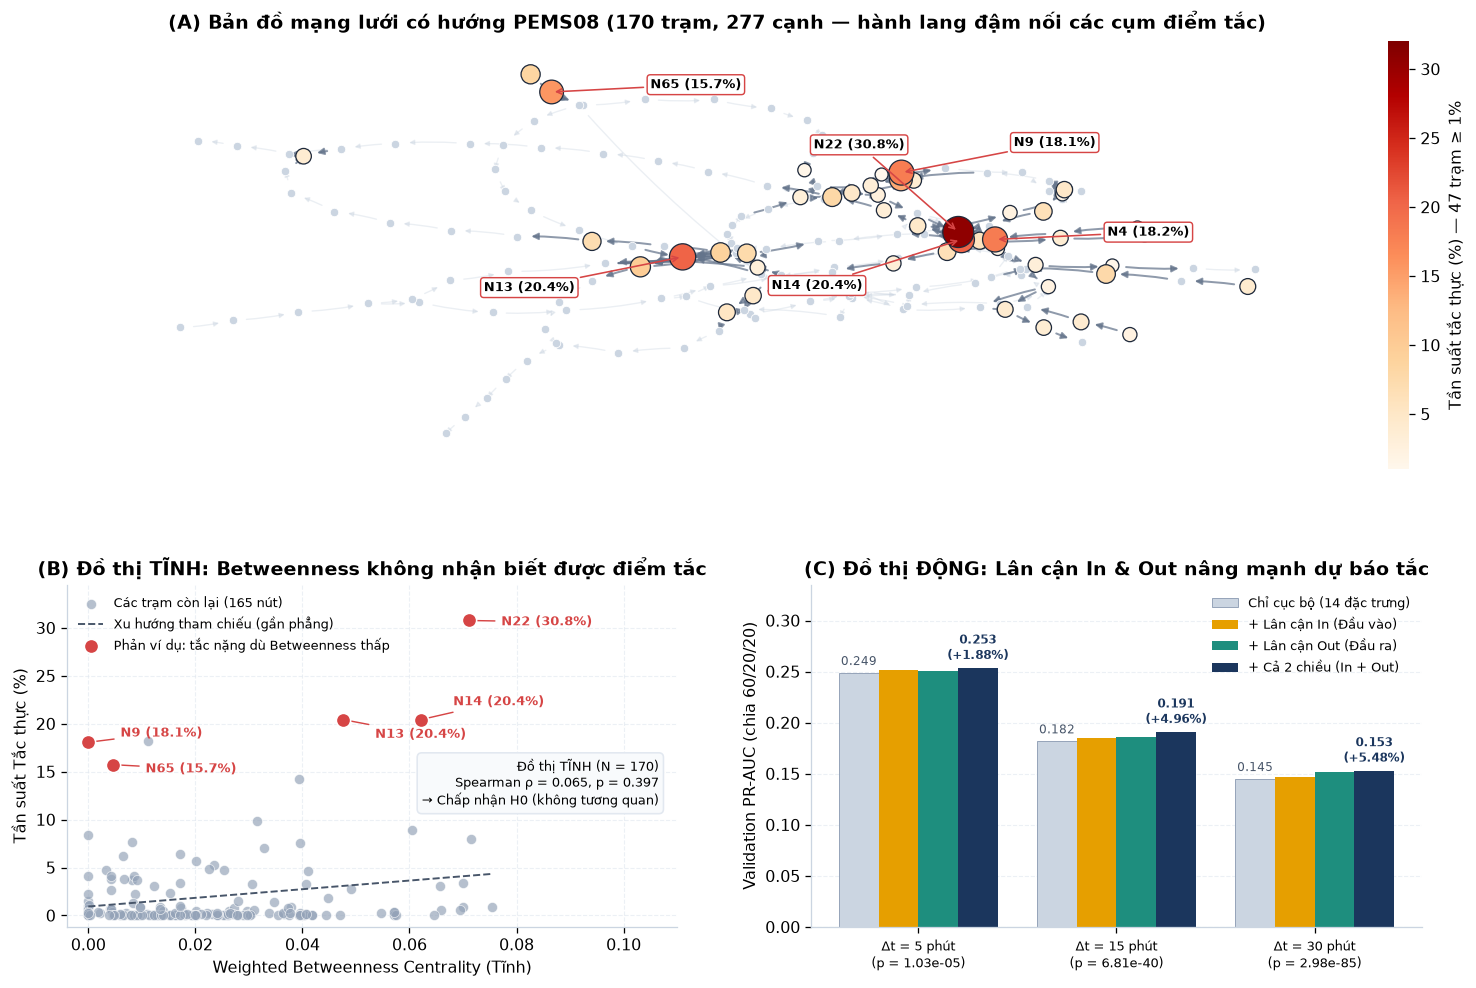

In [10]:
plot_spatial_and_graph(G, st_df, graph_lrt_df, float(rho_b), float(p_b), FIG_DIR / "nb03_spatial_and_betweenness.png")

> **Nhận xét (Tách bạch rõ Đồ thị Tĩnh vs. Đồ thị Động có hướng):**
>
> * **Hình học đồ thị TĨNH không đủ nhận biết điểm tắc (Hình 4B — Li et al., *PNAS* 2015):** Chấp nhận $H_0$ với `Weighted Betweenness` (`Spearman ρ = 0,0654`, `p = 0,3966 > 0,05`) và `Degree` chỉ tương quan rất yếu (`ρ = 0,1859`). Các trạm tắc rất nặng như `N9` (`18,1%`, `Betweenness = 0,0000`) và `N65` (`15,7%`, `Betweenness = 0,0047`) chứng minh chỉ nhìn khung kết nối bản đồ tĩnh sẽ bỏ sót điểm nghẽn.
>
> * **Ngược lại, trạng thái ĐỘNG truyền qua cạnh có hướng `In` và `Out` đóng góp rất mạnh ở tầm xa `15–30p` (Hình 4A & 4C — DCRNN, Li et al., 2018; PDFormer, Jiang et al., AAAI 2023):** Trên nền đủ **`14` đặc trưng cục bộ**, bổ sung trạng thái động của lân cận `In + Out` nâng tiếp `Val PR-AUC` thêm **`+1,88%` (`5p`, `p = 1,03e-05`)**, **`+4,96%` (`15p`, `p = 6,81e-40`, đạt `0,1907`)**, và **`+5,48%` (`30p`, `p = 2,98e-85`, đạt `0,1528`)**. Mức tăng bứt phá ở `15–30p` (với chiều `Out` sóng tắc dội ngược nổi trội) khớp trực tiếp với cơ chế **độ trễ lan truyền không gian (*propagation delay*)** của **PDFormer (2023)** — là căn cứ đưa trực tiếp đồ thị có hướng 2 chiều vào mô hình chú ý đồ thị ở `NB04`.

---
## 5. Tổng kết Câu hỏi Nghiên cứu 1 và Thiết lập Đầu vào cho Mô hình hóa

> **Nhận xét (Tổng kết trọn vẹn RQ1 thuần trên `PEMS08`):**
>
> 1. **Điều kiện tắc nghẽn hướng dữ liệu & loại trừ `Flow` (Phần 2):** Áp dụng quy chuẩn **FHWA (`< 60%` FFS)** và Biểu đồ cơ bản trên `PEMS08` cho $v_{\text{cong}} = \mathbf{40{,}26\text{ mph}}$ và $o_{\text{sat}} = \mathbf{0{,}1325}$ (`59.003` điểm tắc thực = `1,94%`, `99,51%` trong `05–23h`, lọc `4.752` điểm chậm đường vắng). Đã chứng minh `Flow` đa trị do *Capacity Drop* (`-13,7%`, `Flow AUC = 0,7586` vs `Occ AUC = 0,9781`) nên không đặt ngưỡng theo `Flow`.
>
> 2. **Pha chuyển tiếp & chốt đủ `14` đặc trưng cục bộ từ `4` nhóm ngang hàng trên cửa sổ cố định `H = 12` = `60p` (Phần 3):** Xác lập $v_{\text{sync}} = \mathbf{53{,}68\text{ mph}}$ cùng `4` nhóm đặc trưng bổ sung — `3` nhóm tín hiệu tiền tắc nghẽn vật lý (`7` chỉ báo đạt **`AUC = 0,78–0,93`**, $p < 10^{-300}$) và **Nhóm 4 (`4` chu kỳ `STID`: `tod (sin,cos)` `AUC = 0,6878`, `dow (sin,cos)` `0,5635`)**. Khi gộp trọn bộ cả `4` nhóm (`14` đặc trưng), `Val PR-AUC` bứt phá vượt mọi nhóm đơn lẻ, tăng **`+22,51%` đến `+31,66%`** ($p \le 2,70\times 10^{-56}$) so với chỉ `3` biến thô.
>
> 3. **Cấu trúc đồ thị động 2 chiều và bàn giao sang `NB04` (Phần 4):** Hình học tĩnh `Betweenness` không có tác dụng (`p = 0,3966`), nhưng trạng thái động từ lân cận có hướng `In + Out` nâng tiếp `Val PR-AUC` thêm **`+1,88%` (`5p`) đến `+5,48%` (`30p`, $p = 2,98\times 10^{-85}$)**, khớp hiệu ứng độ trễ lan truyền (**PDFormer, 2023**). Bàn giao ma trận đầu vào cố định `H = 12` bước × `14` đặc trưng cùng đồ thị có hướng `PEMS08_network.gexf` và `PEMS08_bottlenecks.csv` sang `NB04`.
>
> **Câu hỏi nghi vấn tiếp theo (Chuyển sang `NB04` — RQ2):**
>
> Khi đưa đồng thời bộ `7` chỉ báo tiền tắc nghẽn và cấu trúc đồ thị có hướng 2 chiều vào các mô hình dự báo chuỗi thời gian – đồ thị (gồm mô hình chú ý đồ thị), chất lượng dự đoán điểm tắc nghẽn tương lai trên `PEMS08` cải thiện bao nhiêu so với chỉ dùng biến gốc, và từng nhóm chỉ báo đóng góp cụ thể như thế nào?